# PropLead AI - Real Estate Lead Conversion Intelligence System
**Analysis notebook** | PGDM - Marketing + Business Analytics

> ⚠️ **Data caveat:** the dataset is **synthetic** (1,200 generated records). Results demonstrate the *workflow and code*;
> they are **not** evidence of real real-estate market behaviour. Replace with authorised, anonymised CRM data for real use.

**Notebook map:** 1 Setup → 2 Load & profile → 3 Cleaning → 4 EDA → 5 Feature engineering → 6 RFE analysis →
7 Priority score → 8 Channel analysis → 9 Conversion model → 10 Recommendations → 11 Limitations

## 1. Setup

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

from src import config, data_cleaning, features, scoring, model, visuals
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
print("Project root:", ROOT)

Project root: /home/claude/PropLead-AI


## 2. Load and profile the raw data

In [2]:
raw = data_cleaning.load_raw()
print("Shape:", raw.shape)
raw.head()

Shape: (1200, 18)


,lead_id,lead_source,campaign_name,city,property_type,preferred_bhk,budget_lakh,website_visits,calls_connected,whatsapp_replies,site_visit_completed,followup_count,response_time_hours,days_since_last_contact,loan_preapproved,discount_interest,lead_status,converted
0,L0001,Website,Web_Organic,Pune,Plot,0,49.6,6,1,5,0,7,4.1,1,0,0,Nurturing,0
1,L0002,Google Ads,GAds_Search_Generic,Pune,Builder Floor,2,126.9,4,0,1,1,2,2.5,6,0,1,Lost,0
2,L0003,Referral,Ref_Broker_Network,Noida,Apartment,3,89.6,7,1,0,1,3,2.7,6,0,0,Lost,0
3,L0004,Website,Web_Brochure_Download,Pune,Villa,3,118.6,4,0,1,1,2,10.3,17,0,1,Lost,0
4,L0005,Property Portal,Portal_Featured_Project,Pune,Apartment,3,48.4,7,1,3,0,2,3.4,12,1,1,Nurturing,0


In [3]:
print(raw.dtypes)
print()
print("Missing values per column:")
print(raw.isna().sum()[raw.isna().sum() > 0])
print()
print("Distinct spellings in lead_source (before cleaning):", raw["lead_source"].nunique())
print(raw["lead_source"].value_counts().tail(8))

lead_id                        str
lead_source                    str
campaign_name                  str
city                           str
property_type                  str
preferred_bhk                int64
budget_lakh                float64
website_visits               int64
calls_connected              int64
whatsapp_replies             int64
site_visit_completed         int64
followup_count               int64
response_time_hours        float64
days_since_last_contact      int64
loan_preapproved             int64
discount_interest            int64
lead_status                    str
converted                    int64
dtype: object

Missing values per column:
city                   12
budget_lakh            18
response_time_hours    30
dtype: int64

Distinct spellings in lead_source (before cleaning): 19
lead_source
property portal    3
 GOOGLE ADS        3
WALK-IN            3
instagram          3
google ads         3
walk in            3
Referal            2
referral           1


## 3. Data cleaning
`src/data_cleaning.py` standardises categories, removes duplicates, validates ranges, imputes missing values
(median by group, with `*_imputed` flags) and caps extreme outliers at the 99th percentile.

In [4]:
df, report = data_cleaning.clean(raw)
import json
print(json.dumps({k: report[k] for k in ["rows_in", "rows_out", "missing_before", "category_fixes",
                                          "exact_duplicates_removed", "duplicate_lead_ids_removed",
                                          "validation_issues", "missing_after"]}, indent=2))
print("Clean lead sources:", report["unique_lead_sources"])

{
  "rows_in": 1200,
  "rows_out": 1200,
  "missing_before": {
    "city": 12,
    "budget_lakh": 18,
    "response_time_hours": 30
  },
  "category_fixes": {
    "lead_source": 48,
    "city": 10,
    "property_type": 8
  },
  "exact_duplicates_removed": 0,
  "duplicate_lead_ids_removed": 0,
  "validation_issues": {},
  "missing_after": {}
}
Clean lead sources: ['Google Ads', 'Instagram', 'Property Portal', 'Referral', 'Walk-in', 'Website']


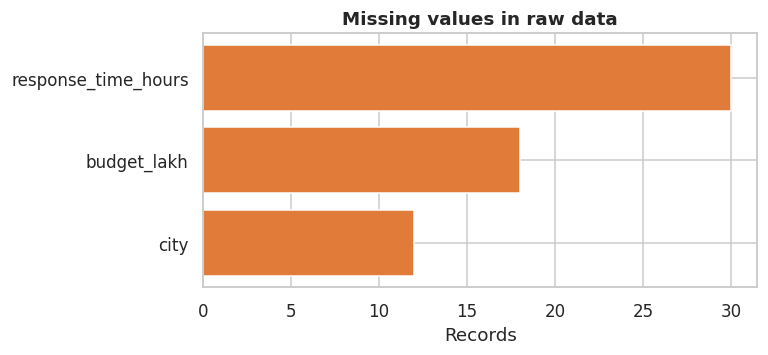

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 3))
miss = raw.isna().sum(); miss = miss[miss > 0].sort_values()
ax.barh(miss.index, miss.values, color="#E07B39"); ax.set_title("Missing values in raw data"); ax.set_xlabel("Records")
plt.show()

## 4. Exploratory data analysis (EDA)

In [6]:
df = features.build_features(df)
print(f"Leads: {len(df):,} | Conversions: {df['converted'].sum()} | Overall conversion rate: {df['converted'].mean():.1%}")
df.describe().T.round(2)

Leads: 1,200 | Conversions: 258 | Overall conversion rate: 21.5%


,count,mean,std,min,25%,50%,75%,max
preferred_bhk,1200.0,2.14,1.40,0.0,1.0,2.0,3.00,5.0
budget_lakh,1200.0,113.20,67.81,19.9,68.2,93.8,138.43,386.1
website_visits,1200.0,3.02,2.07,0.0,2.0,3.0,4.00,10.0
calls_connected,1200.0,1.45,1.38,0.0,0.0,1.0,2.00,8.0
whatsapp_replies,1200.0,1.58,1.33,0.0,1.0,1.0,2.00,7.0
site_visit_completed,1200.0,0.28,0.45,0.0,0.0,0.0,1.00,1.0
followup_count,1200.0,3.10,1.53,1.0,2.0,3.0,4.00,9.0
response_time_hours,1200.0,7.91,6.70,0.3,3.7,6.0,9.90,36.5
days_since_last_contact,1200.0,7.12,7.04,0.0,2.0,5.0,10.00,33.0
loan_preapproved,1200.0,0.39,0.49,0.0,0.0,0.0,1.00,1.0


### 4.1 Lead volume and conversion by source

                 leads  conversions  conv_rate
lead_source                                   
Walk-in            107           37       34.6
Referral           133           44       33.1
Website            173           35       20.2
Instagram          185           35       18.9
Google Ads         264           48       18.2
Property Portal    338           59       17.5


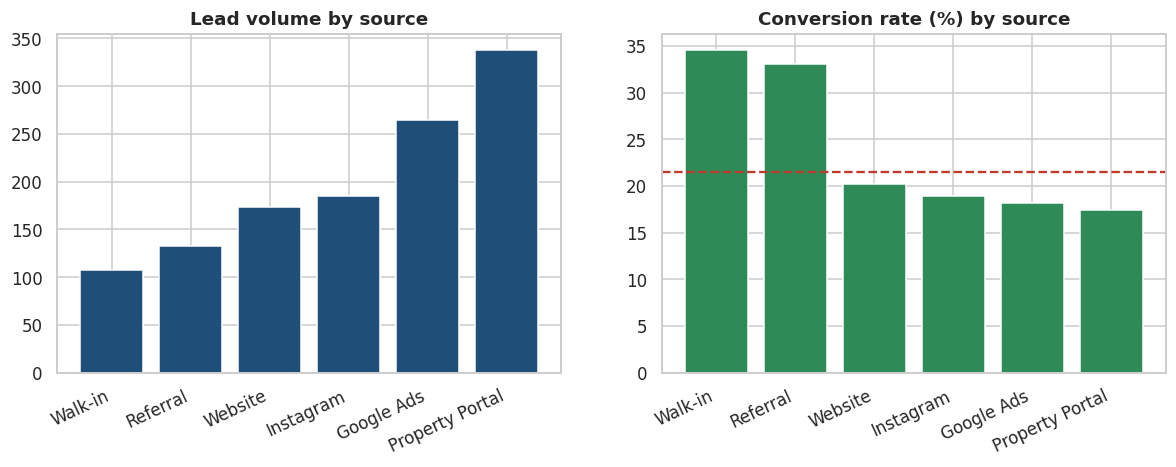

In [7]:
src_tbl = df.groupby("lead_source")["converted"].agg(leads="size", conversions="sum", conv_rate="mean").sort_values("conv_rate", ascending=False)
display_tbl = src_tbl.assign(conv_rate=(src_tbl["conv_rate"] * 100).round(1))
print(display_tbl)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(src_tbl.index, src_tbl["leads"], color="#1F4E79"); axes[0].set_title("Lead volume by source")
axes[1].bar(src_tbl.index, src_tbl["conv_rate"] * 100, color="#2E8B57"); axes[1].set_title("Conversion rate (%) by source")
axes[1].axhline(df["converted"].mean() * 100, color="#C0392B", ls="--")
for ax in axes: plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
plt.show()

### 4.2 Budget (customer-stated) distribution

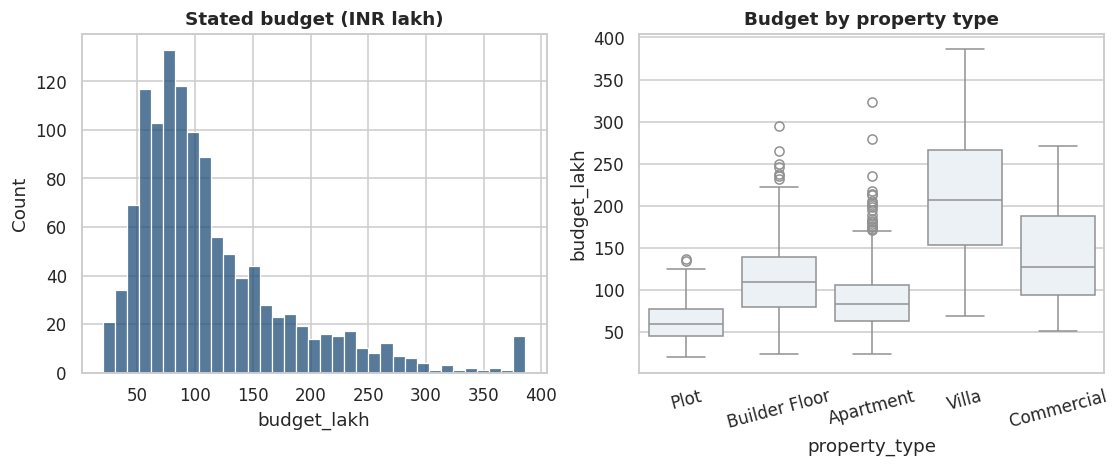

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["budget_lakh"], bins=35, color="#1F4E79", ax=axes[0]); axes[0].set_title("Stated budget (INR lakh)")
sns.boxplot(data=df, x="property_type", y="budget_lakh", color="#EAF1F8", ax=axes[1]); axes[1].set_title("Budget by property type")
plt.setp(axes[1].get_xticklabels(), rotation=15)
plt.show()

### 4.3 City and property-type patterns

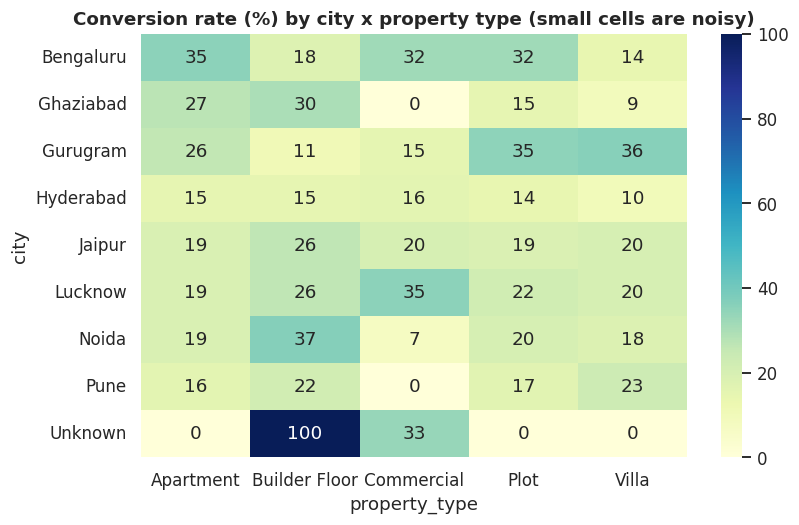

In [9]:
pt = df.pivot_table(index="city", columns="property_type", values="converted", aggfunc="mean") * 100
plt.figure(figsize=(8, 5)); sns.heatmap(pt, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Conversion rate (%) by city x property type (small cells are noisy)"); plt.show()

### 4.4 Engagement, response time and readiness vs conversion

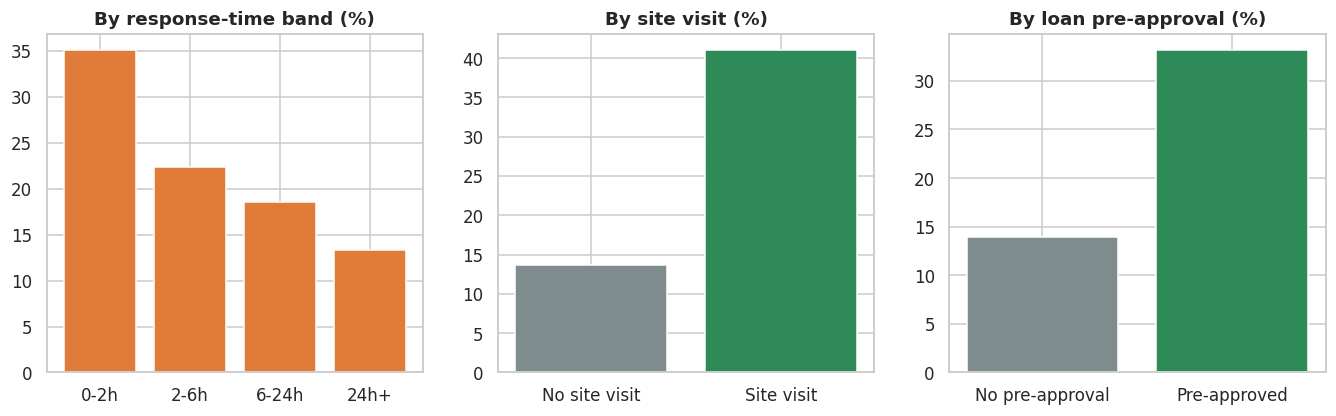

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
resp = df.groupby("response_band", observed=True)["converted"].mean() * 100
axes[0].bar(resp.index.astype(str), resp.values, color="#E07B39"); axes[0].set_title("By response-time band (%)")
sv = df.groupby("site_visit_completed")["converted"].mean() * 100
axes[1].bar(["No site visit", "Site visit"], sv.values, color=["#7F8C8D", "#2E8B57"]); axes[1].set_title("By site visit (%)")
ln = df.groupby("loan_preapproved")["converted"].mean() * 100
axes[2].bar(["No pre-approval", "Pre-approved"], ln.values, color=["#7F8C8D", "#2E8B57"]); axes[2].set_title("By loan pre-approval (%)")
plt.show()

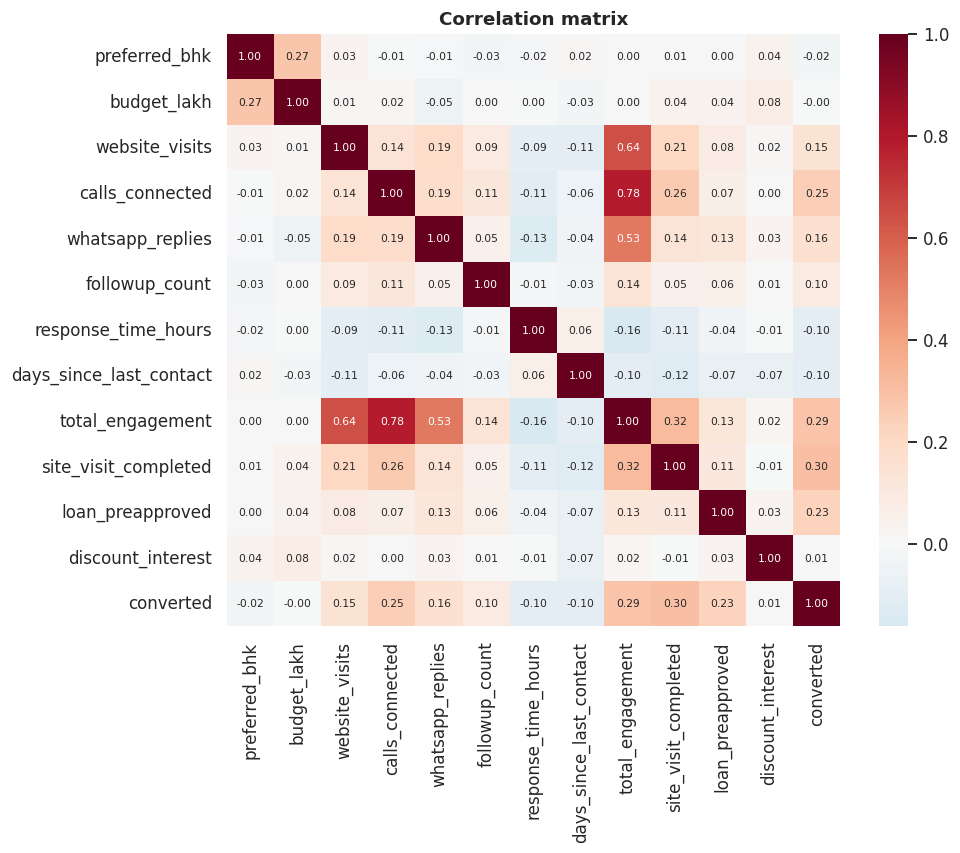

In [11]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[config.NUMERIC_FEATURES + ["converted"]].corr(), cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlation matrix"); plt.show()

## 5. Feature engineering
New columns: `total_engagement` (visits + 2×calls + WhatsApp), `response_band`, `followup_intensity`, `budget_band`,
`readiness_level` (loan pre-approved + site visit done).

In [12]:
df[["lead_id", "total_engagement", "response_band", "followup_intensity", "budget_band", "readiness_level"]].head(8)

,lead_id,total_engagement,response_band,followup_intensity,budget_band,readiness_level
0,L0001,13,2-6h,High (6+),<50L,0
1,L0002,5,2-6h,Low (1-2),100-200L,1
2,L0003,9,2-6h,Medium (3-5),50-100L,1
3,L0004,5,6-24h,Low (1-2),100-200L,1
4,L0005,12,2-6h,Low (1-2),<50L,1
5,L0006,7,24h+,Medium (3-5),50-100L,1
6,L0007,8,6-24h,Medium (3-5),50-100L,1
7,L0008,8,2-6h,Medium (3-5),50-100L,0


## 6. Lead RFM-style (Recency / Frequency / Engagement) analysis
This is a **lead-specific adaptation** of RFM, not classic purchase RFM:
**R** = days since last contact (fewer is better), **F** = follow-ups made, **E** = weighted engagement.
Each is scored 1-5 by quintile; the sum (3-15) maps to Cold / Cool / Warm / Hot.

             leads  conv_rate  avg_recency_days  avg_followups  avg_engagement
rfe_segment                                                                   
Cold           115       0.06             14.96           1.64            3.63
Cool           405       0.15              9.34           2.50            5.59
Warm           461       0.23              5.43           3.33            8.29
Hot            219       0.37              2.48           4.50           11.42


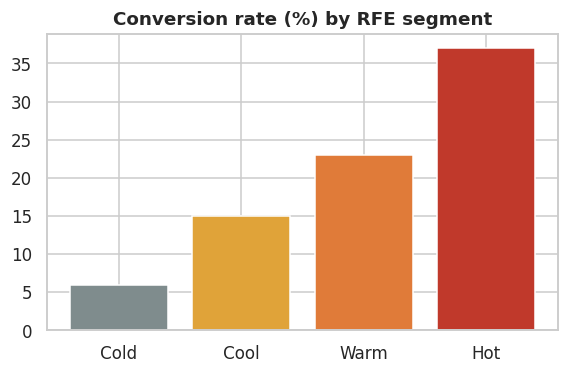

In [13]:
rfe = df.groupby("rfe_segment", observed=True).agg(leads=("converted", "size"), conv_rate=("converted", "mean"),
                                                   avg_recency_days=("days_since_last_contact", "mean"),
                                                   avg_followups=("followup_count", "mean"),
                                                   avg_engagement=("total_engagement", "mean")).round(2)
print(rfe)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(rfe.index.astype(str), rfe["conv_rate"] * 100, color=["#7F8C8D", "#E0A339", "#E07B39", "#C0392B"])
ax.set_title("Conversion rate (%) by RFE segment"); plt.show()

## 7. Explainable lead-priority score
`score = 30·engagement + 20·site_visit + 15·recency + 15·responsiveness + 10·loan_ready + 10·follow-up` (each scaled 0-1 with a documented cap).
Bands: **High ≥ 55**, **Medium ≥ 40**, **Low < 40**. No sensitive personal attributes are used.

               leads  conv_rate
priority_band                  
Low              376      0.061
Medium           443      0.167
High             381      0.423


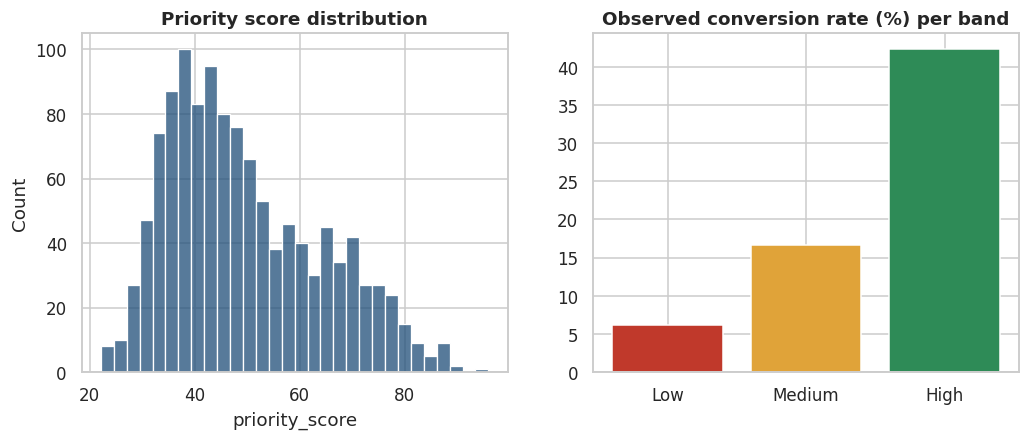

In [14]:
df = scoring.add_priority_score(df)
band = df.groupby("priority_band", observed=True).agg(leads=("converted", "size"), conv_rate=("converted", "mean")).reindex(config.BAND_ORDER)
print(band.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["priority_score"], bins=30, color="#1F4E79", ax=axes[0]); axes[0].set_title("Priority score distribution")
axes[1].bar(band.index.astype(str), band["conv_rate"] * 100, color=[config.BAND_COLORS[b] for b in band.index])
axes[1].set_title("Observed conversion rate (%) per band"); plt.show()

In [15]:
# Explain one lead: which signals produced the score?
example = df.sort_values("priority_score", ascending=False).iloc[0]
print("Lead:", example["lead_id"], "| score:", example["priority_score"], "|", example["priority_band"])
scoring.explain_lead(example)

Lead: L0072 | score: 95.9 | High


,component,points,max_points
0,engagement,28.80,30
1,site_visit,20.00,20
2,recency,14.75,15
3,responsiveness,14.06,15
4,loan_ready,10.00,10
5,followup,8.33,10


In [16]:
df.sort_values("priority_score", ascending=False)[["lead_id", "lead_source", "city", "priority_score", "priority_band", "converted"]].head(10)

,lead_id,lead_source,city,priority_score,priority_band,converted
71,L0072,Google Ads,Lucknow,95.9,High,1
364,L0365,Instagram,Bengaluru,90.5,High,1
819,L0820,Property Portal,Hyderabad,88.9,High,1
167,L0168,Referral,Bengaluru,87.4,High,1
226,L0227,Property Portal,Bengaluru,87.4,High,0
824,L0825,Referral,Jaipur,86.8,High,1
936,L0937,Walk-in,Gurugram,86.6,High,1
1120,L1121,Website,Hyderabad,86.5,High,1
180,L0181,Referral,Bengaluru,86.2,High,1
169,L0170,Walk-in,Lucknow,86.1,High,0


## 8. Channel and revenue-potential analysis
Budget is the **customer-stated budget**, not company revenue. Spend is not in the data, so cost per conversion cannot be computed here.

In [17]:
ch = visuals.channel_summary(df)
ch

,leads,conversions,conversion_rate,median_budget_lakh,total_stated_budget_cr,avg_priority_score,high_priority_share,avg_response_hours
lead_source,,,,,,,,
Walk-in,107,37,0.346,82.30,104.730,46.970,0.271,8.325
Referral,133,44,0.331,95.10,153.055,50.875,0.346,9.113
Website,173,35,0.202,91.80,188.123,50.375,0.318,7.482
Instagram,185,35,0.189,97.30,215.310,50.713,0.341,7.886
Google Ads,264,48,0.182,92.70,293.807,48.666,0.314,7.738
Property Portal,338,59,0.175,95.75,403.364,49.202,0.311,7.661


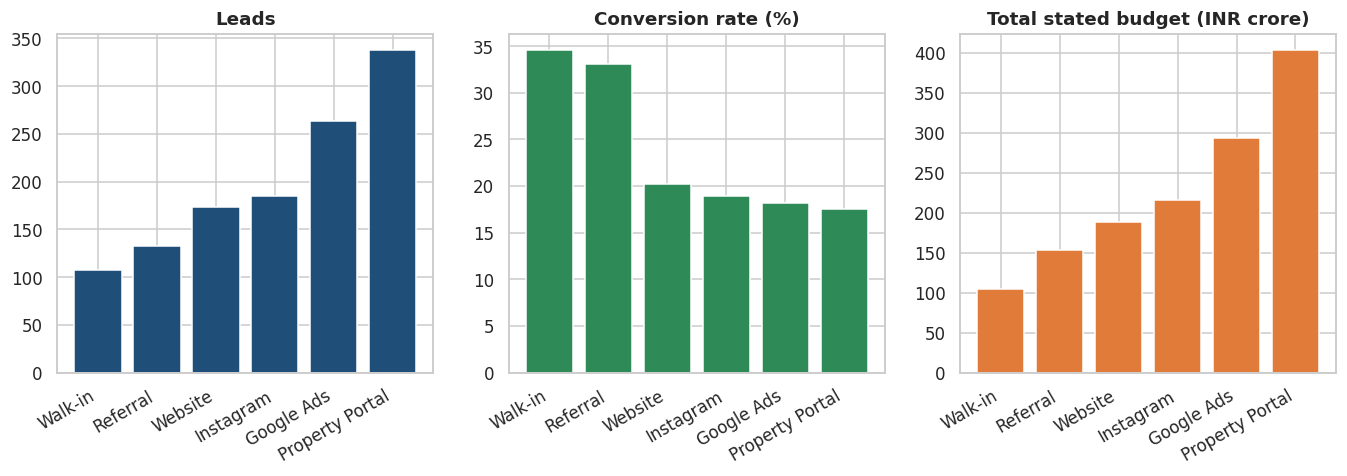

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].bar(ch.index, ch["leads"], color="#1F4E79"); axes[0].set_title("Leads")
axes[1].bar(ch.index, ch["conversion_rate"] * 100, color="#2E8B57"); axes[1].set_title("Conversion rate (%)")
axes[2].bar(ch.index, ch["total_stated_budget_cr"], color="#E07B39"); axes[2].set_title("Total stated budget (INR crore)")
for ax in axes: plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
plt.show()

## 9. Conversion model
**Leakage control:** `lead_status` (recorded after the outcome), `lead_id`, `campaign_name` and the target are excluded.
Models: majority-class baseline, Logistic Regression, Random Forest. Stratified 80/20 split + 5-fold CV on the training set.

In [19]:
print("Features used:", model.FEATURES)
out = model.train_and_evaluate(df, save=False)
res = out["results"]
pd.DataFrame(res["models"]).T

Features used: ['preferred_bhk', 'budget_lakh', 'website_visits', 'calls_connected', 'whatsapp_replies', 'followup_count', 'response_time_hours', 'days_since_last_contact', 'total_engagement', 'site_visit_completed', 'loan_preapproved', 'discount_interest', 'lead_source', 'city', 'property_type']


,precision,recall,f1,roc_auc,pr_auc,cv_roc_auc_mean,cv_roc_auc_std
Baseline (majority class),0.0000,0.0000,0.0000,0.5000,0.2167,0.5000,0.0000
Logistic Regression,0.4366,0.5962,0.5041,0.7448,0.4610,0.7809,0.0304
Random Forest,0.4898,0.4615,0.4752,0.7211,0.4178,0.7796,0.0292


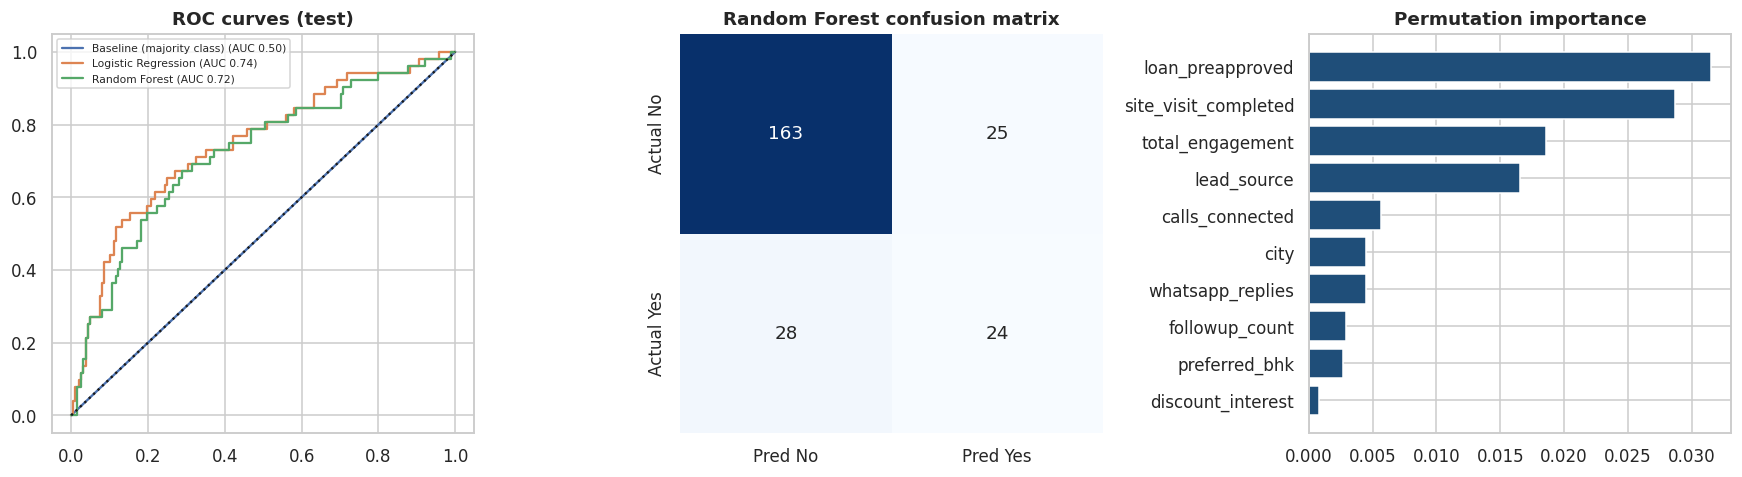

In [20]:
from sklearn.metrics import roc_curve
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for name, (fpr, tpr) in out["curves"].items():
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {res['models'][name]['roc_auc']:.2f})")
axes[0].plot([0, 1], [0, 1], "k:"); axes[0].legend(fontsize=7); axes[0].set_title("ROC curves (test)")
sns.heatmap(np.array(res["confusion_matrix_rf"]), annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1],
            xticklabels=["Pred No", "Pred Yes"], yticklabels=["Actual No", "Actual Yes"]); axes[1].set_title("Random Forest confusion matrix")
imp = out["importance"].head(10).iloc[::-1]
axes[2].barh(imp["feature"], imp["importance"], color="#1F4E79"); axes[2].set_title("Permutation importance")
plt.tight_layout(); plt.show()

In [21]:
lift = out["lift"].round(3)
print(f"Top-decile lift: {res['top_decile_lift']}x | Top-3-decile capture of conversions: {res['top3_deciles_capture']:.0%}")
lift

Top-decile lift: 2.98x | Top-3-decile capture of conversions: 61%


,decile,leads,conversions,conv_rate,avg_prob,lift,cum_capture
0,1,120,77,0.642,0.693,2.984,0.298
1,2,120,46,0.383,0.567,1.783,0.477
2,3,120,34,0.283,0.487,1.318,0.609
3,4,120,26,0.217,0.421,1.008,0.709
4,5,120,24,0.200,0.369,0.930,0.802
5,6,120,16,0.133,0.319,0.620,0.864
6,7,120,13,0.108,0.273,0.504,0.915
7,8,120,4,0.033,0.235,0.155,0.930
8,9,120,12,0.100,0.199,0.465,0.977
9,10,120,6,0.050,0.147,0.233,1.000


## 10. Business recommendations (from the output above)
The full, auto-generated write-up is in `reports/BUSINESS_RECOMMENDATIONS.md`. In short:
1. Order follow-ups by priority band (High first) and allow staff to override.
2. Track and shorten first-response time; test it with a proper SLA experiment before claiming causation.
3. Push engaged leads towards a site visit and loan pre-approval conversations.
4. Review channels using *real* spend data; the weakest converting source needs diagnosis before budget is cut.
5. Collect timestamps, spend and a precise outcome definition in the real CRM.

## 11. Limitations and ethics
- **Synthetic data**: relationships were designed by the author; model metrics say nothing about the real market.
- **Correlation ≠ causation**: e.g. faster response is *associated* with conversion here; this does not prove it causes it.
- **Small hold-out set (240 leads)**: metric differences between models are noisy.
- **Possible leakage in real data**: fields recorded after the outcome must be excluded.
- **Privacy**: never upload names, phone numbers, e-mails or exact addresses; do not score using protected attributes.
- Scores are **estimates for human review**, not guarantees.